# JS07 - Lab Assignment: Clustering of Credit Card Customer Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/ImagesML/'

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv(glob.glob(DATA + 'CC_Customer*')[0])
print(df.shape)
df.head()

Mounted at /content/drive
(660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [3]:
def col(keyword):
    return [c for c in df.columns if keyword.lower() in c.lower().replace(' ', '_')][0]

c_limit = col('avg_credit')
c_cards = col('total_credit')

id_cols = [c for c in df.columns if c.lower().replace(' ', '_') in ('sl_no', 'customer_key', 'id', 'customerid')]
features = [c for c in df.select_dtypes(include=np.number).columns if c not in id_cols]
print("Usable variables:", features)

X_all = StandardScaler().fit_transform(df[features])
X_2d = StandardScaler().fit_transform(df[[c_limit, c_cards]])

Usable variables: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


## 1. Scatterplot: Avg_Credit_Limit vs Total_credit_card

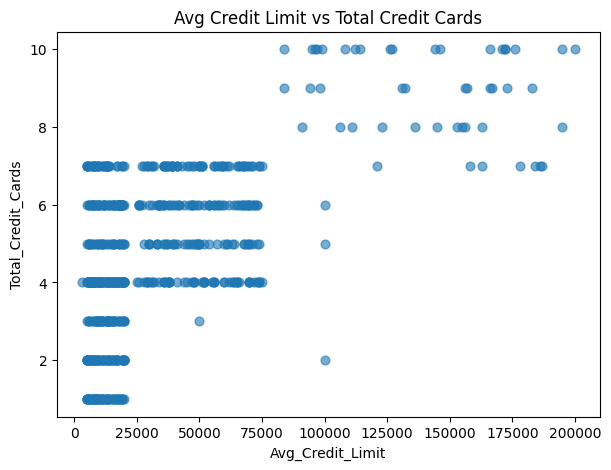

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(df[c_limit], df[c_cards], s=40, alpha=0.6)
plt.xlabel(c_limit); plt.ylabel(c_cards)
plt.title('Avg Credit Limit vs Total Credit Cards')
plt.show()

Answer : The points do not lie along a straight line: the number of cards takes only a few discrete values and the credit limit is spread widely across them, with a dense group at low limits and a sparse tail at high limits. The distribution is therefore not linear.

## 2. K-Means with the Elbow Method

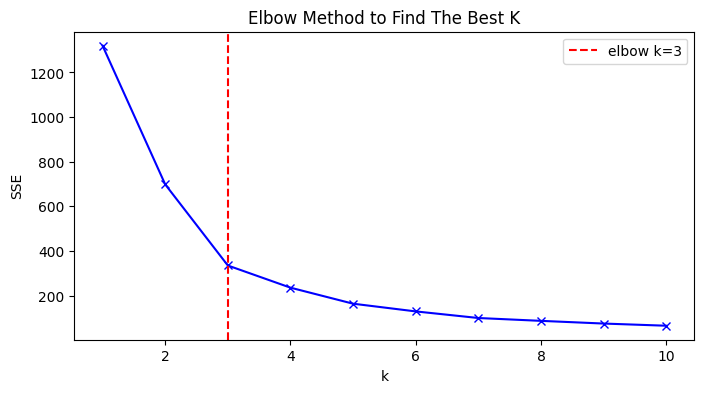

Optimal k: 3


In [5]:
def knee(xs, ys):
    """Point farthest from the line joining the first and last points (elbow)."""
    xs = np.array(xs, float); ys = np.array(ys, float)
    p1 = np.array([xs[0], ys[0]]); p2 = np.array([xs[-1], ys[-1]])
    v = p2 - p1
    pts = np.c_[xs, ys] - p1
    d = np.abs(v[0] * pts[:, 1] - v[1] * pts[:, 0]) / np.linalg.norm(v)
    return xs[np.argmax(d)]

K = range(1, 11)
sse = [KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_2d).inertia_ for k in K]
best_k = int(knee(list(K), sse))

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.axvline(best_k, color='r', linestyle='--', label=f'elbow k={best_k}')
plt.xlabel('k'); plt.ylabel('SSE'); plt.title('Elbow Method to Find The Best K')
plt.legend(); plt.show()
print('Optimal k:', best_k)

Answer : The SSE drops sharply up to the elbow marked on the chart and then declines only slowly. Beyond that point, extra clusters reduce SSE only marginally while making the groups harder to interpret, so the elbow value of k is the best trade-off between compact clusters and simplicity.

## 3. K-Means Clustering Result

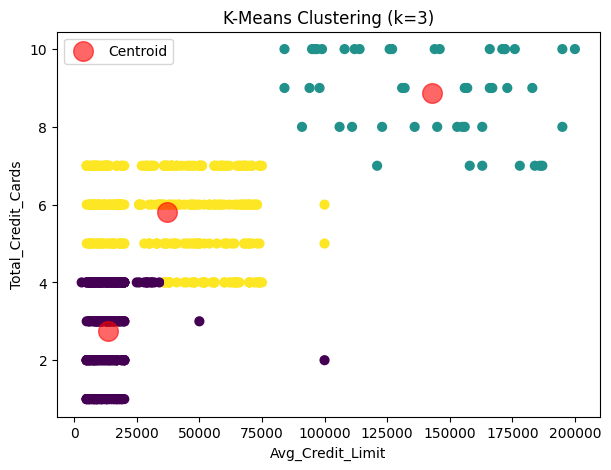

In [6]:
km = KMeans(n_clusters=best_k, random_state=0, n_init=10)
labels_km = km.fit_predict(X_2d)

plt.figure(figsize=(7, 5))
plt.scatter(df[c_limit], df[c_cards], c=labels_km, cmap='viridis', s=40)
centers = StandardScaler().fit(df[[c_limit, c_cards]]).inverse_transform(km.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.6, label='Centroid')
plt.xlabel(c_limit); plt.ylabel(c_cards)
plt.title(f'K-Means Clustering (k={best_k})')
plt.legend(); plt.show()

## 4. DBSCAN with All Usable Variables

## 5. Determining the Optimal eps (k-distance elbow)



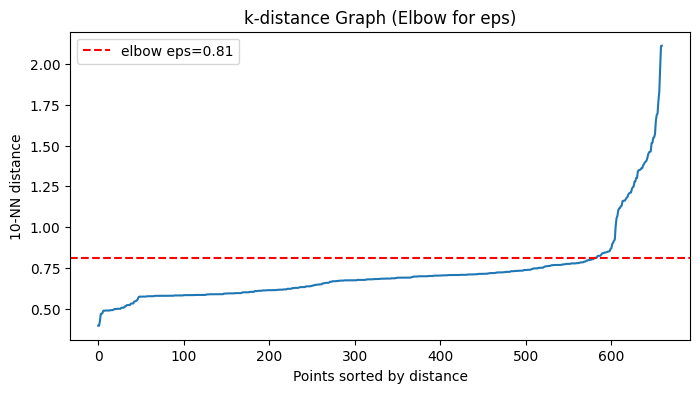

min_samples: 10 | eps: 0.813


In [7]:
min_samples = 2 * len(features)
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_all)
dist, _ = nn.kneighbors(X_all)
kdist = np.sort(dist[:, -1])

idx = np.arange(len(kdist))
eps = float(kdist[int(knee(idx, kdist))])

plt.figure(figsize=(8, 4))
plt.plot(kdist)
plt.axhline(eps, color='r', linestyle='--', label=f'elbow eps={eps:.2f}')
plt.xlabel('Points sorted by distance'); plt.ylabel(f'{min_samples}-NN distance')
plt.title('k-distance Graph (Elbow for eps)')
plt.legend(); plt.show()
print('min_samples:', min_samples, '| eps:', round(eps, 3))

Answer : The k-distance curve rises slowly for most points and then bends upward sharply. The distance at that bend is chosen as `eps`: smaller values would label many normal customers as noise, larger values would merge distinct groups into one.

Clusters: 1 | Noise points: 54 (8.2%)


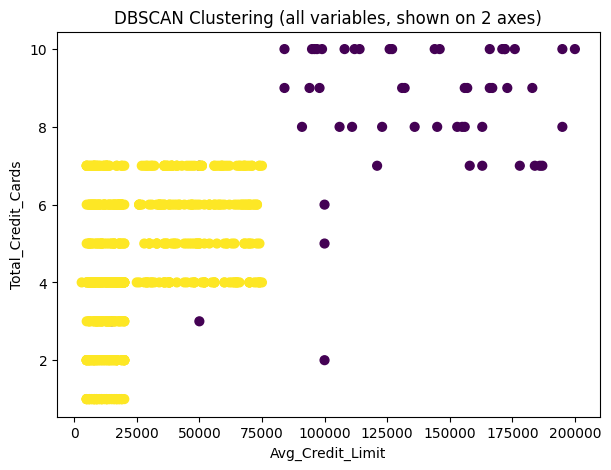

In [8]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels_db = dbscan.fit_predict(X_all)

n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = int((labels_db == -1).sum())
print(f'Clusters: {n_clusters} | Noise points: {n_noise} ({n_noise / len(labels_db):.1%})')

plt.figure(figsize=(7, 5))
plt.scatter(df[c_limit], df[c_cards], c=labels_db, cmap='viridis', s=40)
plt.xlabel(c_limit); plt.ylabel(c_cards)
plt.title('DBSCAN Clustering (all variables, shown on 2 axes)')
plt.show()

## 6. Silhouette Score and DBI of DBSCAN

In [9]:
mask = labels_db != -1

if len(set(labels_db[mask])) >= 2:
    print('Silhouette score:', silhouette_score(X_all[mask], labels_db[mask]))
    print('Davies-Bouldin Index:', davies_bouldin_score(X_all[mask], labels_db[mask]))
else:
    print('DBSCAN found fewer than 2 clusters; adjust eps / min_samples.')

DBSCAN found fewer than 2 clusters; adjust eps / min_samples.
